# 峰到原子的指认

将实测 NMR 峰与已知分子结构中的原子对应起来。

先用 NMRNet 预测逐原子化学位移，再合并对称相关位点，通过最小代价匹配把实测峰与预测位点对应。输出包含原子编号、预测位移、匹配残差和备选指认。

本教程读取保存的预测，解释输入输出字段，并评估结果。最后给出在新数据集上运行模型的命令。

In [1]:
import json, sys, io
from pathlib import Path
from IPython.display import display, Markdown, SVG
root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'openmolspec_bench').is_dir()), None)
if root is None:
    raise RuntimeError('Run from the cloned release repository; see Quick Start')
sys.path.insert(0, str(root / 'scripts'))
from documentation_evidence import load_evidence, compact, recompute, render
from documentation_content import results_table
evidence = load_evidence('nmr.assignment')
print('Task:', evidence['task'])
print('Examples:', len(evidence['examples']))

Task: nmr.assignment
Examples: 3


## 输入与输出

| Field | Meaning |
| --- | --- |
| `smiles` | 已知分子结构。 |
| `nucleus / peaks_ppm` | 1H 或 13C，以及实测一维峰位置（ppm）。 |
| `tolerance_ppm` | 峰与预测位点的最大允许残差，默认 H 0.5、C 5 ppm。 |

| Field | Meaning |
| --- | --- |
| `assignments` | 峰编号 → 候选原子编号、预测位移、残差与备选位点。 |
| `unmatched` | 未匹配峰与预测位点的编号。 |

查看下面的示例记录。长数组显示长度与前几个数值，下载 JSON 可获取完整数组。

In [2]:
for example in evidence['examples'][:3]:
    print(json.dumps(compact(example), indent=2, ensure_ascii=False))

{
  "input": {
    "smiles": "C=C(CCCCc1ccccc1)c1ccc(C(C)(C)C)cc1",
    "nucleus": "13C",
    "peaks_ppm": {
      "length": 16,
      "first_values": [
        150.22,
        148.03,
        142.68,
        138.28,
        128.36,
        128.22,
        125.68,
        125.58
      ]
    },
    "note": "Assigned observed peaks; unmatched indices retained in output"
  },
  "output": {
    "smiles": "C=C(CCCCc1ccccc1)c1ccc(C(C)(C)C)cc1",
    "symbol": "C",
    "mapped_smiles": "[C:1](=[C:2]([C:3]([C:4]([C:5]([C:6]([c:7]1[c:8]([H:33])[c:9]([H:34])[c:10]([H:35])[c:11]([H:36])[c:12]1[H:37])([H:31])[H:32])([H:29])[H:30])([H:27])[H:28])([H:25])[H:26])[c:13]1[c:14]([H:38])[c:15]([H:39])[c:16]([C:17]([C:18]([H:40])([H:41])[H:42])([C:19]([H:43])([H:44])[H:45])[C:20]([H:46])([H:47])[H:48])[c:21]([H:49])[c:22]1[H:50])([H:23])[H:24]",
    "atom_index_basis": "zero-based RDKit AddHs(input_smiles); atom-map numbers = index + 1",
    "equivalence": "topological symmetry including chirality; not pro

## 评估预测

用峰覆盖率和匹配峰 MAE 汇总指认结果。

表格给出每次运行的数据集与指标。后续代码从绘图使用的预测值重新计算汇总结果。

In [3]:
display(Markdown(results_table(evidence, False)))
print(json.dumps(recompute(evidence), indent=2, ensure_ascii=False))

| Dataset / scope | Model / variant | Metric | Value |
| --- | --- | --- | ---: |
| recorded evaluation | recorded model | molecules | 32 |
| recorded evaluation | recorded model | matched_peaks | 488 |
| recorded evaluation | recorded model | matched_peak_fraction_macro | 0.939238 |
| recorded evaluation | recorded model | matched_residual_mae_ppm | 0.899131 |
| recorded evaluation | recorded model | assignment_accuracy | not measured |


{
  "matched_peaks_this_example": 16,
  "residual_mae_ppm_this_example": 0.4150966421763089,
  "assignment_accuracy": null
}


## 查看结果图

分子结构上的峰指认。

比较预测与参考，查看返回的结构或峰位置。图由上方读取的记录直接生成。

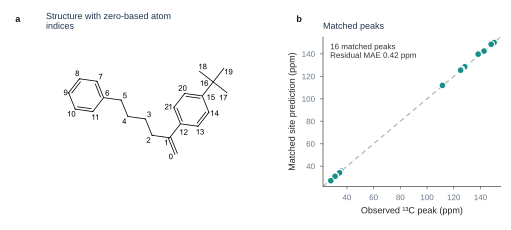

In [4]:
import matplotlib.pyplot as plt
for example_index in range(1):
    figure = render('nmr.assignment', evidence, example_index=example_index)
    image = io.StringIO()
    figure.savefig(image, format='svg', metadata={'Date': None})
    display(SVG(image.getvalue()))
    plt.close(figure)

## 运行模型

按任务指南配置环境和权重，在 benchmark runner 中选择本任务，即可评估自己的数据集。

```bash
python -m openmolspec_bench run --workspace /path/to/OpenMolSpec \
  --tasks nmr.assignment --limit 8 --output results/nmr-assignment.json
```

[Task](../tasks/nmr-assignment.md) · [Quick start](../quickstart.md)



## 参考文献

- Xu, F., Guo, W., Wang, F., Yao, L., Wang, H., Tang, F., Gao, Z., Zhang, L., E, W., Tian, Z.-Q., et al. Toward a unified benchmark and framework for deep learning-based prediction of nuclear magnetic resonance chemical shifts. Nature Computational Science 5, 292–300 (2025). doi:10.1038/s43588-025-00783-z. [Source](https://doi.org/10.1038/s43588-025-00783-z)
- OpenDataLab. WanJuan MolSpectra, version 1.0.3. Experimental molecular spectroscopy dataset. [Source](https://opendatalab.com/)
